# 04 — Regressão: clima → rendimento de café

O rendimento agora é **de café** (CONAB), ligado ao clima por **UF + ano**. Não há mais transferência de outra base.

Cuidados de validação:
- todas as regiões de uma UF têm o mesmo rendimento no ano, então a validação cruzada agrupa **por ano** (um ano inteiro fica no treino ou no teste);
- o rendimento tem tendência de alta, então comparamos modelos **só com clima** e **clima + ano**;
- um modelo que sempre prevê a média (*baseline*) mostra o piso a superar;
- um teste temporal (treino até 2018, teste 2019–2025) mostra o desempenho em anos futuros.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/processed/dataset_modelagem.csv')
clima_cols = ['temperatura_media', 'precipitacao_anual', 'umidade', 'radiacao_solar', 'dias_chuva']
y = df['rendimento_t_ha']
grupos = df['ano']
print(df.shape)

(200, 13)


In [2]:
modelos = {
    'Baseline (média)': DummyRegressor(),
    'Regressão linear': LinearRegression(),
    'Árvore (CART)': DecisionTreeRegressor(max_depth=3, random_state=42),
    'KNN (k=5)': KNeighborsRegressor(n_neighbors=5),
}
cenarios = {'Só clima': clima_cols, 'Clima + ano': clima_cols + ['ano']}

cv = GroupKFold(n_splits=5)
linhas, scores = [], {}
for cen, cols in cenarios.items():
    for nome, modelo in modelos.items():
        pipe = make_pipeline(StandardScaler(), modelo)
        s = cross_val_score(pipe, df[cols], y, cv=cv, groups=grupos, scoring='r2')
        scores[(cen, nome)] = s
        linhas.append({'cenario': cen, 'modelo': nome, 'R2_medio': s.mean(), 'R2_desvio': s.std()})
comparacao = pd.DataFrame(linhas).round(3)
comparacao

,cenario,modelo,R2_medio,R2_desvio
0,Só clima,Baseline (média),-0.035,0.043
1,Só clima,Regressão linear,0.098,0.165
2,Só clima,Árvore (CART),-0.019,0.450
3,Só clima,KNN (k=5),-0.006,0.229
4,Clima + ano,Baseline (média),-0.035,0.043
5,Clima + ano,Regressão linear,0.370,0.252
6,Clima + ano,Árvore (CART),0.161,0.380
7,Clima + ano,KNN (k=5),0.295,0.295


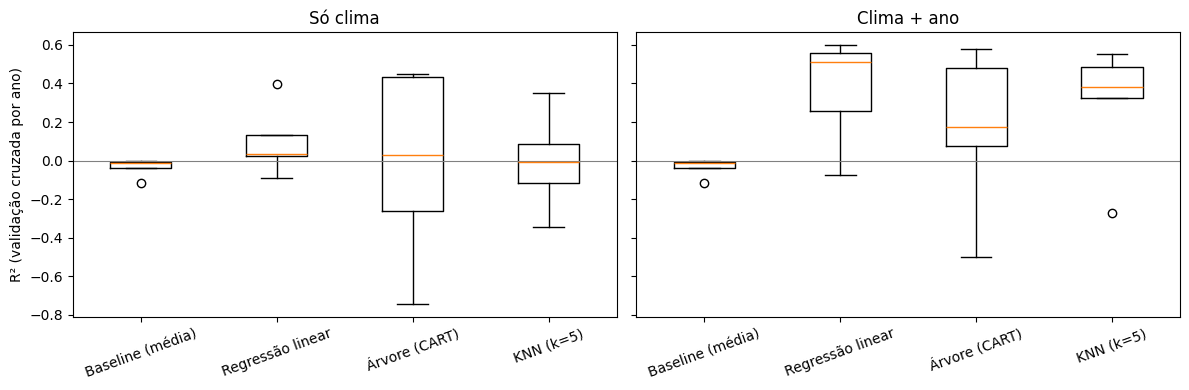

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cen in zip(eixos, cenarios):
    ax.boxplot([scores[(cen, n)] for n in modelos], tick_labels=list(modelos))
    ax.set_title(cen); ax.tick_params(axis='x', rotation=20); ax.axhline(0, color='gray', lw=0.8)
eixos[0].set_ylabel('R² (validação cruzada por ano)')
plt.tight_layout()
plt.savefig('../data/processed/comparacao_modelos.png', bbox_inches='tight')
plt.show()
comparacao.to_csv('../data/processed/comparacao_modelos.csv', index=False)

## Teste temporal: treino 2001–2018, teste 2019–2025

In [4]:
treino = df['ano'] <= 2018
teste = ~treino
linhas = []
preds = {}
for cen, cols in cenarios.items():
    for nome, modelo in modelos.items():
        pipe = make_pipeline(StandardScaler(), modelo).fit(df.loc[treino, cols], y[treino])
        p = pipe.predict(df.loc[teste, cols])
        preds[(cen, nome)] = p
        linhas.append({
            'cenario': cen, 'modelo': nome,
            'MAE': mean_absolute_error(y[teste], p),
            'RMSE': mean_squared_error(y[teste], p) ** 0.5,
            'R2': r2_score(y[teste], p),
        })
temporal = pd.DataFrame(linhas).round(3)
temporal

,cenario,modelo,MAE,RMSE,R2
0,Só clima,Baseline (média),0.386,0.533,-0.919
1,Só clima,Regressão linear,0.358,0.510,-0.757
2,Só clima,Árvore (CART),0.368,0.499,-0.684
3,Só clima,KNN (k=5),0.372,0.540,-0.975
4,Clima + ano,Baseline (média),0.386,0.533,-0.919
5,Clima + ano,Regressão linear,0.396,0.439,-0.305
6,Clima + ano,Árvore (CART),0.386,0.452,-0.379
7,Clima + ano,KNN (k=5),0.328,0.428,-0.241


In [5]:
temporal.to_csv('../data/processed/teste_temporal.csv', index=False)
melhor = temporal.loc[temporal['cenario'] == 'Só clima'].sort_values('R2').iloc[-1]
print('Melhor modelo só com clima no teste temporal:', melhor['modelo'], '| R2 =', melhor['R2'])

saida = df.loc[teste, ['regiao', 'uf', 'ano', 'rendimento_t_ha']].copy()
saida['previsto_so_clima'] = preds[('Só clima', melhor['modelo'])]
saida.round(3).to_csv('../data/processed/previsoes_teste.csv', index=False)
saida.head()

Melhor modelo só com clima no teste temporal: Árvore (CART) | R2 = -0.684


,regiao,uf,ano,rendimento_t_ha,previsto_so_clima
18,Espirito Santo Afonso,ES,2019,2.056044,1.388958
19,Espirito Santo Afonso,ES,2020,2.092199,1.388958
20,Espirito Santo Afonso,ES,2021,2.122555,1.388958
21,Espirito Santo Afonso,ES,2022,2.492701,1.388958
22,Espirito Santo Afonso,ES,2023,1.988084,1.388958


## Coeficientes da regressão linear (só clima)

Com as variáveis padronizadas, o sinal e o tamanho de cada coeficiente mostram quanto cada variável de clima pesa no rendimento.

In [6]:
pipe = make_pipeline(StandardScaler(), LinearRegression()).fit(df[clima_cols], y)
pd.Series(pipe[-1].coef_, index=clima_cols).round(3).sort_values()

precipitacao_anual   -0.138
radiacao_solar       -0.025
dias_chuva            0.033
umidade               0.067
temperatura_media     0.101
dtype: float64